In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("data/diabetic_data.csv")

print("Dataset Shape:", df.shape)

display(df.head())


FileNotFoundError: [Errno 2] No such file or directory: 'data/diabetic_data.csv'

In [4]:
import os

# Current folder location
print("Current Location:", os.getcwd())

# Show all files and folders
print("Files:", os.listdir())

Current Location: C:\Users\Soumyajit Das
Files: ['-1.14-windows.xml', '.anaconda', '.android', '.bash_history', '.claude', '.claude.json', '.codex', '.conda', '.continuum', '.copilot', '.gitconfig', '.idlerc', '.ipynb_checkpoints', '.ipython', '.jupyter', '.lesshst', '.ms-ad', '.node_repl_history', '.openjfx', '.vscode', '.vscode-shared', 'anaconda3', 'ansel', 'AppData', 'Application Data', 'bluej', 'Contacts', 'Cookies', 'CrossDevice', 'Documents', 'Downloads', 'exemple 1', 'Favorites', 'Hospital Readmission Prediction.ipynb', 'Links', 'Local Settings', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{8cb946ad-2a4e-11f0-8b15-d1d98c60fa4a}.TM.blf', 'NTUSER.DAT{8cb946ad-2a4e-11f0-8b15-d1d98c60fa4a}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{8cb946ad-2a4e-11f0-8b15-d1d98c60fa4a}.TMContainer00000000000000000002.regtrans-ms', 'ntuser.ini', 'OneDrive', 'Pictures', 'PrintHood', 'project 1', 'project.php', 'Recent', 'Saved Game

In [5]:
import pandas as pd

df = pd.read_csv("data/diabetic_data.csv")

print("Dataset Shape:", df.shape)

df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'data/diabetic_data.csv'

In [6]:
import os

folder = r"C:\Users\Soumyajit Das\OneDrive\Documents\hospital_readmission_prediction"

print(os.listdir(folder))
print("Data folder:", os.listdir(folder + r"\data"))

['data', 'IDS_mapping.csv', 'photo-gallery', 'photo-gallery.zip']
Data folder: ['diabetic_data.csv']


In [7]:
import pandas as pd

df = pd.read_csv(
    r"C:\Users\Soumyajit Das\OneDrive\Documents\hospital_readmission_prediction\data\diabetic_data.csv"
)

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [8]:
print("Readmission categories:")
print(df["readmitted"].value_counts())

print("\nMissing values in the dataset:")
print(df.isnull().sum().sum())

Readmission categories:
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

Missing values in the dataset:
181168


In [9]:
# Create a target column for 30-day readmission

df["target"] = (df["readmitted"] == "<30").astype(int)

print("Target distribution:")
print(df["target"].value_counts())

print("\nTarget percentages:")
print(df["target"].value_counts(normalize=True) * 100)

Target distribution:
target
0    90409
1    11357
Name: count, dtype: int64

Target percentages:
target
0    88.840084
1    11.159916
Name: proportion, dtype: float64


In [10]:
# Check missing values in each column

missing = df.isnull().sum()

print("Columns with missing values:")
print(missing[missing > 0].sort_values(ascending=False))

print("\nTotal missing values:", df.isnull().sum().sum())

Columns with missing values:
max_glu_serum    96420
A1Cresult        84748
dtype: int64

Total missing values: 181168


In [11]:
# Replace missing test results
df["max_glu_serum "] =df["mx_glu_serum"].fillna("Not Tested")
df["A1Cresult"] = df["A1Cresult"].fillna("Not Tested")
print("Missing values after cleaning:")
print(df.isnull().sum().sum())
print("\nDataset shape:")
print(df.shape)
print("\nCleaning completed!")

KeyError: 'mx_glu_serum'

In [12]:
# Replace missing test results
df["max_glu_serum"] = df["max_glu_serum"].fillna("Not Tested")
df["A1Cresult"] = df["A1Cresult"].fillna("Not Tested")

print("Missing values after cleaning:")
print(df.isnull().sum().sum())
print("\nDataset shape:")
print(df.shape)
print("\nCleaning completed!")


Missing values after cleaning:
0

Dataset shape:
(101766, 51)

Cleaning completed!


In [13]:
X = df.drop(    columns=["readmitted", "target", "encounter_id", "patient_nbr"] ) 
y = df["target"] 
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nFirst 5 rows of features:") 
display(X.head())
print("\nFirst 5 target values:")
print(y.head())

Features shape: (101766, 47)
Target shape: (101766,)

First 5 rows of features:


,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,...,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed
0,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,...,No,No,No,No,No,No,No,No,No,No
1,Caucasian,Female,[10-20),?,1,1,7,3,?,?,...,No,No,Up,No,No,No,No,No,Ch,Yes
2,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,...,No,No,No,No,No,No,No,No,No,Yes
3,Caucasian,Male,[30-40),?,1,1,7,2,?,?,...,No,No,Up,No,No,No,No,No,Ch,Yes
4,Caucasian,Male,[40-50),?,1,1,7,1,?,?,...,No,No,Steady,No,No,No,No,No,Ch,Yes



First 5 target values:
0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64


In [16]:
import os
import pandas as pd

path = os.path.join(os.path.expanduser("~"), "Downloads", "diabetic_data.csv")
print("Looking at:", path)

df = pd.read_csv(r"C:\Users\YourUsername\Downloads\diabetic_data.csv")
print("Dataset loaded successfully!")


Looking at: C:\Users\Soumyajit Das\Downloads\diabetic_data.csv


FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\YourUsername\\Downloads\\diabetic_data.csv'

In [17]:
import pandas as pd

df = pd.read_csv(r"C:\Users\Soumyajit Das\OneDrive\Documents\hospital_readmission_prediction\data\diabetic_data.csv")
print("Dataset loaded successfully!")


Dataset loaded successfully!


In [18]:
df["target"] = (df["readmitted"] == "<30").astype(int)
df["max_glu_serum"] = df["max_glu_serum"].fillna("Not Tested")
df["A1Cresult"] = df["A1Cresult"].fillna("Not Tested")

print("Data preparation completed!")


Data preparation completed!


In [19]:
X = df.drop(
    columns=["readmitted", "target", "encounter_id", "patient_nbr"]
)
y = df["target"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
display(X.head())
print(y.head())


Features shape: (101766, 47)
Target shape: (101766,)


,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,...,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed
0,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,...,No,No,No,No,No,No,No,No,No,No
1,Caucasian,Female,[10-20),?,1,1,7,3,?,?,...,No,No,Up,No,No,No,No,No,Ch,Yes
2,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,...,No,No,No,No,No,No,No,No,No,Yes
3,Caucasian,Male,[30-40),?,1,1,7,2,?,?,...,No,No,Up,No,No,No,No,No,Ch,Yes
4,Caucasian,Male,[40-50),?,1,1,7,1,?,?,...,No,No,Steady,No,No,No,No,No,Ch,Yes


0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64


In [20]:
import numpy as np

# Replace ? with missing values
X = X.replace("?", np.nan)

# Check missing values
print("Missing values in X:")
print(X.isnull().sum().sort_values(ascending=False).head(15))


Missing values in X:
weight                      98569
medical_specialty           49949
payer_code                  40256
race                         2273
diag_3                       1423
diag_2                        358
diag_1                         21
admission_source_id             0
discharge_disposition_id        0
time_in_hospital                0
num_lab_procedures              0
num_procedures                  0
admission_type_id               0
age                             0
gender                          0
dtype: int64


In [21]:
# Fill missing values in categorical columns
X = X.fillna("Unknown")

# Check missing values again
print("Total missing values:", X.isnull().sum().sum())
print("\nDataset shape:", X.shape)
print("\nMissing values handled successfully!")


Total missing values: 0

Dataset shape: (101766, 47)

Missing values handled successfully!


In [22]:
from sklearn.preprocessing import OrdinalEncoder

# Select categorical columns
categorical_columns = X.select_dtypes(include=["object"]).columns

# Convert text values into numerical values
encoder = OrdinalEncoder()
X[categorical_columns] = encoder.fit_transform(
    X[categorical_columns].astype(str)
)

print("Categorical columns converted successfully!")
print("\nFeatures shape:", X.shape)
print("\nFirst 5 rows:")
display(X.head())


C:\Users\Soumyajit Das\AppData\Local\Temp\ipykernel_25024\3451880305.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(include=["object"]).columns


Categorical columns converted successfully!

Features shape: (101766, 47)

First 5 rows:


,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,...,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed
0,2.0,0.0,0.0,1.0,6,25,1,1,16.0,37.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1,2.0,0.0,1.0,1.0,1,1,7,3,16.0,71.0,...,0.0,0.0,3.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0.0,0.0,2.0,1.0,1,1,7,2,16.0,71.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0
3,2.0,1.0,3.0,1.0,1,1,7,2,16.0,71.0,...,0.0,0.0,3.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
4,2.0,1.0,4.0,1.0,1,1,7,1,16.0,71.0,...,0.0,0.0,2.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0


In [23]:
from sklearn.model_selection import train_test_split

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Display the dataset sizes
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)


Training data: (81412, 47)
Testing data: (20354, 47)

Training target: (81412,)
Testing target: (20354,)


In [24]:
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

# Train the model
model.fit(X_train, y_train)

print("Random Forest Model trained successfully!")


Random Forest Model trained successfully!


In [25]:
# Make predictions using testing data
y_pred = model.predict(X_test)

print("Predictions completed successfully!")
print("\nFirst 10 actual values:")
print(y_test.head(10).values)
print("\nFirst 10 predicted values:")
print(y_pred[:10])


Predictions completed successfully!

First 10 actual values:
[0 0 0 1 1 0 0 0 0 0]

First 10 predicted values:
[0 0 0 0 0 0 0 0 0 0]


In [26]:
from sklearn.metrics import accuracy_score, classification_report

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Model Accuracy:", accuracy * 100, "%")

# Display performance report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Model Accuracy: 88.64596639481182 %

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.99      0.94     18083
           1       0.43      0.05      0.09      2271

    accuracy                           0.89     20354
   macro avg       0.66      0.52      0.52     20354
weighted avg       0.84      0.89      0.84     20354



In [27]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# 1. Recreate the original features
X_raw = df.drop(
    columns=["readmitted", "target", "encounter_id", "patient_nbr"]
).replace("?", np.nan)
y = df["target"]

# 2. Identify categorical and numerical columns
categorical_cols = X_raw.select_dtypes(
    include=["object", "str"]
).columns
numerical_cols = X_raw.select_dtypes(
    include=["number"]
).columns

# 3. Prepare categorical data
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# 4. Prepare numerical data
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# 5. Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("cat", categorical_transformer, categorical_cols),
    ("num", numerical_transformer, numerical_cols)
])

# 6. Create the complete ML pipeline
model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# 7. Split the original data
X_train, X_test, y_train, y_test = train_test_split(
    X_raw, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 8. Train the improved model
model.fit(X_train, y_train)

# 9. Make predictions
y_pred = model.predict(X_test)

# 10. Evaluate the model
print("Improved Model Accuracy:", accuracy_score(y_test, y_pred) * 100, "%")
print("\nImproved Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Improved Model Accuracy: 88.80318364940553 %

Improved Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.99      0.94     18083
           1       0.48      0.04      0.07      2271

    accuracy                           0.89     20354
   macro avg       0.68      0.52      0.51     20354
weighted avg       0.85      0.89      0.84     20354



In [28]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_recall_curve
)
import numpy as np

# 1. Divide training data into training and validation sets
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# 2. Train the model using only the smaller training set
model.fit(X_subtrain, y_subtrain)

# 3. Get readmission probabilities for validation data
y_val_prob = model.predict_proba(X_val)[:, 1]

# 4. Find precision and recall at different thresholds
precision, recall, thresholds = precision_recall_curve(
    y_val, y_val_prob
)

# 5. Find thresholds that achieve at least 20% recall
valid = np.where(recall[:-1] >= 0.20)[0]

if len(valid) > 0:
    best_index = valid[np.argmax(precision[valid])]
    best_threshold = thresholds[best_index]
    print("Selected Threshold:", best_threshold)
    print("Validation Precision:", precision[best_index])
    print("Validation Recall:", recall[best_index])

    # 6. Evaluate on the untouched test data
    y_test_prob = model.predict_proba(X_test)[:, 1]
    y_test_pred = (y_test_prob >= best_threshold).astype(int)

    print("\nTest Classification Report:")
    print(classification_report(
        y_test, y_test_pred, zero_division=0
    ))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_test_pred))
else:
    print("No threshold achieved the required recall.")


Selected Threshold: 0.35
Validation Precision: 0.25206611570247933
Validation Recall: 0.20143093010456797

Test Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.93      0.91     18083
           1       0.26      0.20      0.23      2271

    accuracy                           0.85     20354
   macro avg       0.58      0.56      0.57     20354
weighted avg       0.83      0.85      0.84     20354

Confusion Matrix:
[[16744  1339]
 [ 1808   463]]


                                      Feature  Importance
2277                  num__num_lab_procedures    0.046810
2279                     num__num_medications    0.043566
2282                    num__number_inpatient    0.035954
2276                    num__time_in_hospital    0.034540
2274            num__discharge_disposition_id    0.028692
2283                    num__number_diagnoses    0.025124
2278                      num__num_procedures    0.023972
2273                   num__admission_type_id    0.017959
2275                 num__admission_source_id    0.015765
2280                   num__number_outpatient    0.012078
2281                    num__number_emergency    0.011485
5                          cat__gender_Female    0.010559
6                            cat__gender_Male    0.010474
61    cat__medical_specialty_InternalMedicine    0.009738
15                           cat__age_[70-80)    0.009572


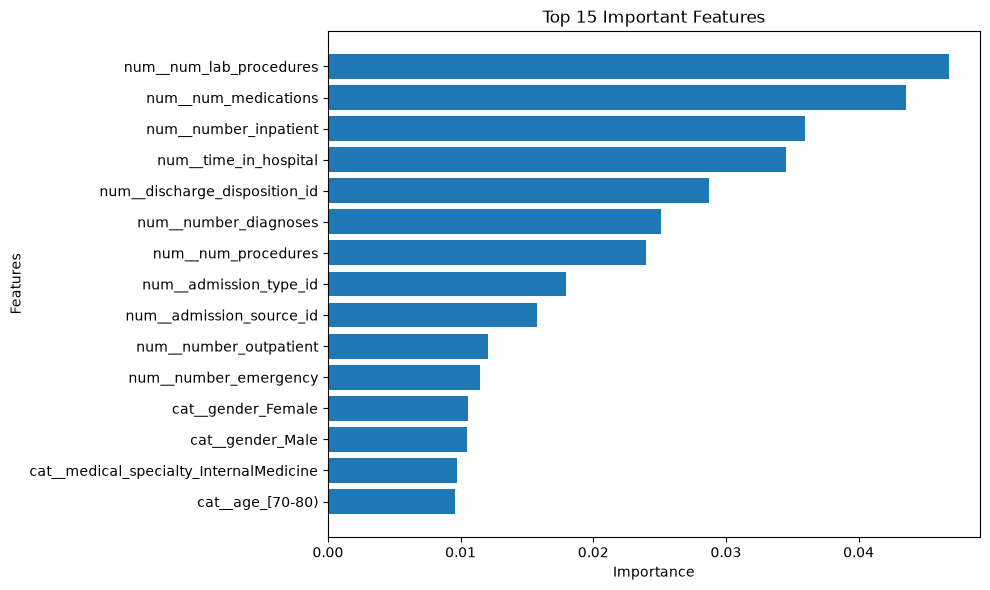

In [29]:
import pandas as pd
import matplotlib.pyplot as plt

# Get the trained Random Forest model
rf_model = model.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = model.named_steps[
    "preprocessing"
].get_feature_names_out()

# Get feature importance values
importance = rf_model.feature_importances_

# Create a DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 features
print(feature_importance.head(15))

# Plot feature importance
plt.figure(figsize=(10, 6))
plt.barh(
    feature_importance.head(15)["Feature"][::-1],
    feature_importance.head(15)["Importance"][::-1]
)
plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Top 15 Important Features")
plt.tight_layout()
plt.show()


In [30]:
import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Load dataset with your exact OneDrive path
df = pd.read_csv(r"C:\Users\Soumyajit Das\OneDrive\Documents\hospital_readmission_prediction\data\diabetic_data.csv")
df["target"] = (df["readmitted"] == "<30").astype(int)

# 2. Select 14 features for the app
selected_features = [
    "race", "gender", "age",
    "admission_type_id", "discharge_disposition_id", "admission_source_id",
    "time_in_hospital", "num_lab_procedures", "num_procedures",
    "num_medications", "number_outpatient", "number_emergency",
    "number_inpatient", "number_diagnoses"
]

X_app = df[selected_features].replace("?", np.nan)
y_app = df["target"]

# 3. Separate categorical and numerical columns
categorical_cols = [
    "race", "gender", "age",
    "admission_type_id", "discharge_disposition_id", "admission_source_id"
]
numerical_cols = [col for col in selected_features if col not in categorical_cols]

# 4. Preprocessing pipelines
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

preprocessor = ColumnTransformer(transformers=[
    ("cat", categorical_transformer, categorical_cols),
    ("num", numerical_transformer, numerical_cols)
])

# 5. Split data by patient
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_index, test_index = next(splitter.split(X_app, y_app, groups=df["patient_nbr"]))

X_train_app = X_app.iloc[train_index]
X_test_app = X_app.iloc[test_index]
y_train_app = y_app.iloc[train_index]
y_test_app = y_app.iloc[test_index]

# 6. Create and train the 14-feature Random Forest pipeline
app_model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

app_model.fit(X_train_app, y_train_app)
print("14-feature model trained successfully!")

# 7. Evaluate model
y_pred_app = app_model.predict(X_test_app)
print("\nModel Accuracy:", accuracy_score(y_test_app, y_pred_app) * 100, "%")
print("\nClassification Report:")
print(classification_report(y_test_app, y_pred_app, zero_division=0))

# 8. Save model
joblib.dump(app_model, "hospital_readmission_model.pkl")
print("\nNew model saved successfully!")


14-feature model trained successfully!

Model Accuracy: 87.43115168957475 %

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.97      0.93     18002
           1       0.26      0.09      0.14      2151

    accuracy                           0.87     20153
   macro avg       0.58      0.53      0.53     20153
weighted avg       0.83      0.87      0.85     20153


New model saved successfully!


In [31]:
import numpy as np
import joblib
from sklearn.base import clone
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    precision_recall_curve,
    classification_report,
    confusion_matrix
)

# Separate training data into training and validation groups
groups_train = df["patient_nbr"].iloc[train_index]
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)
subtrain_idx, val_idx = next(
    splitter.split(X_train_app, y_train_app, groups_train)
)

# Create a temporary model
validation_model = clone(app_model)

# Train using the smaller training set
validation_model.fit(
    X_train_app.iloc[subtrain_idx],
    y_train_app.iloc[subtrain_idx]
)

# Get validation probabilities
val_prob = validation_model.predict_proba(
    X_train_app.iloc[val_idx]
)[:, 1]

# Calculate precision and recall
precision, recall, thresholds = precision_recall_curve(
    y_train_app.iloc[val_idx],
    val_prob
)

# Select threshold with at least 20% recall
valid = np.where(recall[:-1] >= 0.20)[0]

if len(valid) > 0:
    best_index = valid[np.argmax(precision[valid])]
    best_threshold = thresholds[best_index]
else:
    best_index = np.argmax(recall[:-1])
    best_threshold = thresholds[best_index]

print("Selected Threshold:", best_threshold)
print("Validation Precision:", precision[best_index])
print("Validation Recall:", recall[best_index])

# Evaluate on untouched test data
test_prob = app_model.predict_proba(X_test_app)[:, 1]
test_pred = (test_prob >= best_threshold).astype(int)

print("\nFinal Test Classification Report:")
print(classification_report(
    y_test_app,
    test_pred,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test_app, test_pred))

# Save the selected threshold
joblib.dump(
    best_threshold,
    "readmission_threshold.pkl"
)
print("\nThreshold saved successfully!")


Selected Threshold: 0.4
Validation Precision: 0.2236619718309859
Validation Recall: 0.21150772509323387

Final Test Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.90      0.90     18002
           1       0.20      0.21      0.21      2151

    accuracy                           0.83     20153
   macro avg       0.55      0.56      0.56     20153
weighted avg       0.83      0.83      0.83     20153

Confusion Matrix:
[[16259  1743]
 [ 1703   448]]

Threshold saved successfully!


In [33]:
import os

os.chdir(r"C:\Users\Soumyajit Das\OneDrive\Documents\hospital_readmission_prediction")

with open(".gitignore", "w") as f:
    f.write("hospital_readmission_model.pkl\n.ipynb_checkpoints/\n")

!git init
!git add .
!git commit -m "Hospital readmission prediction project"
!git branch -M main
!git remote add origin https://github.com
!git push -u origin main


Reinitialized existing Git repository in C:/Users/Soumyajit Das/OneDrive/Documents/hospital_readmission_prediction/.git/
On branch main
Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
  (commit or discard the untracked or modified content in submodules)
	modified:   photo-gallery/photo-gallery (modified content)

no changes added to commit (use "git add" and/or "git commit -a")


error: remote origin already exists.
fatal: repository 'https://github.com/' not found


In [34]:
import os

os.chdir(r"C:\Users\Soumyajit Das\OneDrive\Documents\hospital_readmission_prediction")

!git remote set-url origin https://github.com/byb3887-wq/hospital-readmission-prediction.git
!git branch -M main
!git push -u origin main


branch 'main' set up to track 'origin/main'.


To https://github.com/byb3887-wq/hospital-readmission-prediction.git
 * [new branch]      main -> main


In [35]:
import os

os.chdir(r"C:\Users\Soumyajit Das\OneDrive\Documents\hospital_readmission_prediction")

!git rm -r --cached photo-gallery photo-gallery.zip
!git commit -m "Remove unwanted files"
!git push origin main


rm 'photo-gallery.zip'
rm 'photo-gallery/package-lock.json'
rm 'photo-gallery/photo-gallery'
[main 5080450] Remove unwanted files
 3 files changed, 7 deletions(-)
 delete mode 100644 photo-gallery.zip
 delete mode 100644 photo-gallery/package-lock.json
 delete mode 160000 photo-gallery/photo-gallery


To https://github.com/byb3887-wq/hospital-readmission-prediction.git
   ebe334b..5080450  main -> main


In [36]:
import os
print(os.getcwd())


C:\Users\Soumyajit Das\OneDrive\Documents\hospital_readmission_prediction


In [37]:
import os

os.chdir(r"C:\Users\Soumyajit Das\OneDrive\Documents\hospital_readmission_prediction")

print("Files in folder:", os.listdir())

!git add -f *.ipynb *.py
!git commit -m "Add project code"
!git push origin main


Files in folder: ['.git', '.gitignore', 'data', 'IDS_mapping.csv', 'photo-gallery', 'photo-gallery.zip']


fatal: pathspec '*.ipynb' did not match any files


On branch main
Your branch is up to date with 'origin/main'.

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	photo-gallery.zip
	photo-gallery/

nothing added to commit but untracked files present (use "git add" to track)


Everything up-to-date
